# Homework 1

completed by **Alina Khurges**

Please send a link to a public github repository with your file and the file of the chosen novel or a link to a public google colab file to daschapopowa@gmail.com

Due October 3rd, 23:59

    Choose a long text, a novel, in Russian or in English
    Lemmatize the novel. -- 1 point
    Choose a word from the lemmatized novel that is common for that novel and extract from the lemmatized novel all its children (all its syntactic dependencies) and all the children of its children (secondary dependencies). -- 2 points
    Create a graph, depicting the result of (3). At the center of the graph would be your chosen word, around it all its dependencies, around those all their dependencies. Set the parameters: what the color and the size of the nodes and the width of the edges stands for. Choose a directed or a non-directed graph. Describe and justify your choices of the parameters. -- 2 points
    Perform network analysis of the graph. Mesure the density, split the graph into communities etc. Describe and justify what and why you are doing. -- 2 points
    Could you draw any meaningful conclusions from your analysis? Provide a short (a couple of sentences) answer. -- 1 point





## 1. Lemmatizing the novel

I am using "Котлован" by Andrei Platonov because I had it on hand...

In [1]:
with open("Котлован 1930.txt", 'r', encoding="utf-8") as f:
  novel = "\n".join(f.readlines()[10:]) # started from the first line of the novel, removing the author / title
print(novel[:100]) # this is indeed the beginning of the novel

В день тридцатилетия личной жизни Вощеву дали расчет с небольшого механического завода, где он добыв


I am using nltk for tokenization and pymorphy3 for lemmatization. Alternatively, pymystem3 could be used for lemmatization.

(I have some concerns about whether lemmatizing the text before finding the dependencies could affect the results; perhaps using an unlemmatized text and ".lemma_" in SpaCy would make finding the dependencies more accurate? Although maybe this would result in the lemmatization being much less accurate than here, where I use a module designed specifically for Russian..? Regardless, I am following the instructions as given)

In [2]:
!pip install pymorphy3 --q

In [3]:
from nltk.tokenize import wordpunct_tokenize
from pymorphy3 import MorphAnalyzer

In [4]:
morph = MorphAnalyzer()

In [5]:
tokens = wordpunct_tokenize(novel)
lemmatized = " ".join([morph.parse(item)[0].normal_form for item in tokens])

In [6]:
lemmatized[:300]

'в день тридцатилетие личный жизнь вощева дать расчёт с небольшой механический завод , где он добывать средство для свой существование . в увольнительный документ он написать , что он устраняться с производство вследствие рост слабосильность в немой и задумчивость среди общий темп труд . вощев взять '

(We may note that the lemmatization is not managing the name Вощев very successfully; everything else in this small fragment, however, seems to be working as intended)

## 2. A word and its syntactic dependencies

**The task:** Choose a word from the lemmatized novel that is common for that novel and extract from the lemmatized novel all its children (all its syntactic dependencies) and all the children of its children (secondary dependencies).

In [7]:
!pip install -U pip setuptools wheel
!pip install -U spacy
! python -m spacy download ru_core_news_sm

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 15.3/15.3 MB 33.4 MB/s  0:00:00
✔ Download and installation successful
You can now load the package via spacy.load('ru_core_news_sm')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.


In [8]:
import spacy
nlp = spacy.load("ru_core_news_sm")

In [9]:
d = nlp(lemmatized)

I picked a noun ("колхоз"). Here I just print out its children and their children alongside their part of speech tags and the labels for their syntactic relations (I show the latter out of curiosity; I did not end up using them in the graph in any way).

In [10]:
for token in d:
    if token.text == "колхоз":
        for child in token.children:
            print("сhild: ", child.text, child.pos_, child.dep_)
            for grandchild in child.children:
                print("grandchild: ", grandchild.text, grandchild.pos_, grandchild.dep_)

сhild:  по ADP case
сhild:  по ADP case
сhild:  у ADP case
сhild:  имя NOUN nmod
сhild:  от ADP case
сhild:  над ADP case
сhild:  бедный ADJ amod
сhild:  в ADP case
сhild:  путём NOUN nmod
сhild:  , PUNCT punct
сhild:  как SCONJ case
сhild:  идти VERB xcomp
grandchild:  свет NOUN obl
сhild:  — PUNCT punct
сhild:  ведь PART advmod
сhild:  на ADP case
сhild:  без ADP case
сhild:  , PUNCT punct
сhild:  в ADP case
сhild:  в ADP case
сhild:  обождать VERB nmod
grandchild:  иль NOUN obl
сhild:  в ADP case
сhild:  в ADP case
сhild:  — PUNCT punct
сhild:  ты PRON nsubj
сhild:  в ADP case
сhild:  в ADP case
сhild:  в ADP case
сhild:  в ADP case
сhild:  весь DET det
сhild:  — PUNCT punct
сhild:  а CCONJ cc
сhild:  ты PRON nsubj
сhild:  здесь ADV advmod
сhild:  сделать VERB xcomp
сhild:  ? PUNCT punct
сhild:  спасть NOUN nmod
grandchild:  ещё ADV advmod
сhild:  в ADP case
сhild:  на ADP case
сhild:  в ADP case
сhild:  в ADP case
сhild:  зимой NOUN nmod
сhild:  — PUNCT punct
сhild:  мы PRON nsubj


Just to illustrate: if I had picked a relatively common verb, it would have so many children and grandchildren! (The main problem I see with this is making a somewhat readable graph; I do not know how to achieve it with this many dependencies...)

In [11]:
# look how many children!
for token in d:
    if token.text == "жить":
        for child in token.children:
            print("сhild: ", child.text, child.pos_, child.dep_)
            for grandchild in child.children:
                print("grandchild: ", grandchild.text, grandchild.pos_, grandchild.dep_)

сhild:  , PUNCT punct
сhild:  она PRON nsubj
сhild:  рождение NOUN obl
grandchild:  благодаря ADP case
grandchild:  один NUM nummod
сhild:  я PRON obl
grandchild:  , PUNCT punct
grandchild:  как SCONJ case
grandchild:  и PART advmod
сhild:  питаться VERB conj
grandchild:  и CCONJ cc
сhild:  пойти VERB conj
grandchild:  , PUNCT punct
grandchild:  поэтому ADV advmod
grandchild:  он PRON nsubj
grandchild:  завком ADJ obl
сhild:  , PUNCT punct
сhild:  ты PRON nsubj
сhild:  бы AUX aux
сhild:  и PART advmod
сhild:  молчать VERB xcomp
сhild:  , PUNCT punct
сhild:  он PRON nsubj
сhild:  мочь ADV advmod
сhild:  изнемогать VERB xcomp
grandchild:  не PART advmod
grandchild:  место NOUN obl
grandchild:  томиться VERB conj
сhild:  , PUNCT punct
сhild:  а CCONJ cc
сhild:  ребёнок NOUN obj
сhild:  упрёк NOUN obl
grandchild:  без ADP case
сhild:  — PUNCT punct
сhild:  вы PRON obl
grandchild:  у ADP case
сhild:  ребёнок NOUN obj
сhild:  ругаться VERB conj
grandchild:  , PUNCT punct
grandchild:  а CCONJ

## 3. The graph
**The task:** Create a graph, depicting the result of (2). At the center of the graph would be your chosen word, around it all its dependencies, around those all their dependencies. Set the parameters: what the color and the size of the nodes and the width of the edges stands for. Choose a directed or a non-directed graph. Describe and justify your choices of the parameters.

AI disclosure: the AI deepseek was consulted during the making of the graph, largely with questions like "this is my code, how do I modify it to also make the nodes different colors depending on their part of speech"

In [12]:
!pip install networkx

In [13]:
import networkx as nx

My decisions about the graph:
* I use a directed graph to illustrate the dependencies more clearly (the direction of the arrows indicates what depends on what).
* Moreover, I chose different edge colors for primary dependencies (children) and secondary dependencies (grandchildren), so that the two are easy to distinguish.
* The width of the edge reflects the weight (how common the dependency is), and the color of the node reflects the part of speech of the word.

(I tried to illustrate about as many things as possible here; the downside is that it might be making the graph too busy; at some point I thought about indicating the amount of times each dependency occurred, but, to my mind, that made the graph too hard to read. I imagine that the dependency labels (that provide information about the syntactic relationship between the head & the dependent) could also be interesting to illustrate, though I also imagine that the chance of two wordforms that have different syntactic relationships to the same head but the same lemma is higher than for them to have different part of speech tags...).

In [14]:
import matplotlib.pyplot as plt

In [15]:
from collections import Counter

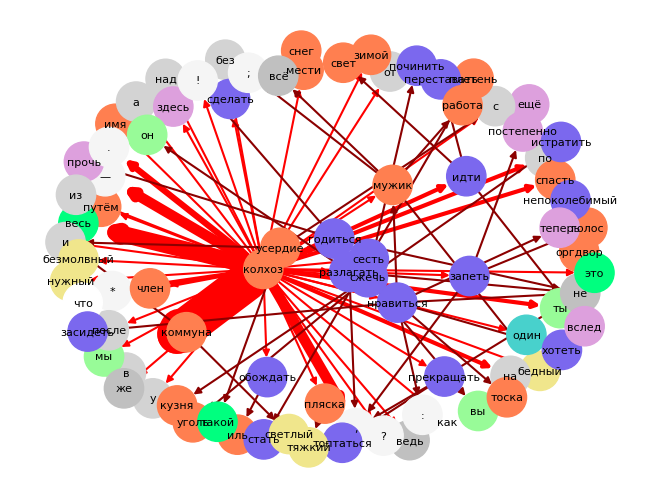

In [21]:
pos_colors = {
    "NOUN":  "coral",
    "VERB":  "mediumslateblue",
    "ADJ":   "khaki",
    "ADV":   "plum",
    "PRON":  "palegreen",
    "DET": "springgreen",
    "NUM": "mediumturquoise",
    "PART": "silver",
    "ADP":   "lightgray",
    "CCONJ": "lightgray",
    "PUNCT": "whitesmoke",
}
default_color = "white"


counts = Counter()
for token in d:
    if token.text == "колхоз":
        for child in token.children:
            counts[("колхоз", child.text)] += 1
            for grandchild in child.children:
                counts[(child.text, grandchild.text)] += 1

G = nx.DiGraph()
for (u, v), w in counts.items():
    G.add_edge(u, v, weight=w)

word_pos = {}
for token in d:
    if token.text in G and token.text not in word_pos:
        word_pos[token.text] = token.pos_

pos = nx.spring_layout(G, weight="weight", seed=42) # so that the weights of the dependencies affect their position

widths = [G[u][v]["weight"] * 1.5 for u, v in G.edges]
# edge_labels = {(u, v): G[u][v]["weight"] for u, v in G.edges} # we could show the number of times the dependency occurred like this
# but i think it gets somewhat unwieldy
edge_colors = ["red" if u == "колхоз" else "darkred" for u, v in G.edges]
node_colors = [pos_colors.get(word_pos.get(n, ""), default_color) for n in G.nodes]


nx.draw(G, pos, with_labels=True,
        node_color=node_colors, node_size=800,
        edge_color=edge_colors, width=widths,
        arrows=True, font_size=8)
 # nx.draw_networkx_edge_labels(G, pos, edge_labels=edge_labels, font_size=8) # to show the number of times each dependency occurred on the arrow
plt.axis("off")
plt.show()

Here I simply print out the nodes and the edges.

In [22]:
print('nodes', G.nodes())
print('edges', G.edges())

nodes ['колхоз', 'по', 'у', 'имя', 'от', 'над', 'бедный', 'в', 'путём', ',', 'как', 'идти', 'свет', '—', 'ведь', 'на', 'без', 'обождать', 'иль', 'ты', 'весь', 'а', 'здесь', 'сделать', '?', 'спасть', 'ещё', 'зимой', 'мы', 'нужный', 'разлагать', 'не', 'он', '!', 'годиться', 'вы', 'прочь', 'с', 'прекращать', 'топтаться', 'пляска', 'тяжкий', 'запеть', 'постепенно', 'голос', '.', 'непоколебимый', 'оргдвор', 'один', 'же', 'из', '*', 'член', 'сжечь', 'уголь', 'кузня', 'истратить', 'починить', 'тоска', 'сесть', 'плетень', 'стать', 'после', 'коммуна', 'и', 'светлый', 'что', 'это', 'мести', 'снег', 'нравиться', ':', 'мужик', 'теперь', 'засидеть', 'хотеть', 'безмолвный', 'вслед', 'переставать', ';', 'всё', 'работа', 'усердие', 'такой']
edges [('колхоз', 'по'), ('колхоз', 'у'), ('колхоз', 'имя'), ('колхоз', 'от'), ('колхоз', 'над'), ('колхоз', 'бедный'), ('колхоз', 'в'), ('колхоз', 'путём'), ('колхоз', ','), ('колхоз', 'как'), ('колхоз', 'идти'), ('колхоз', '—'), ('колхоз', 'ведь'), ('колхоз', 'на

Just to illustrate, here is the equivalent process but with a common verb at the center. The graph is unfortunately quite unreadable...

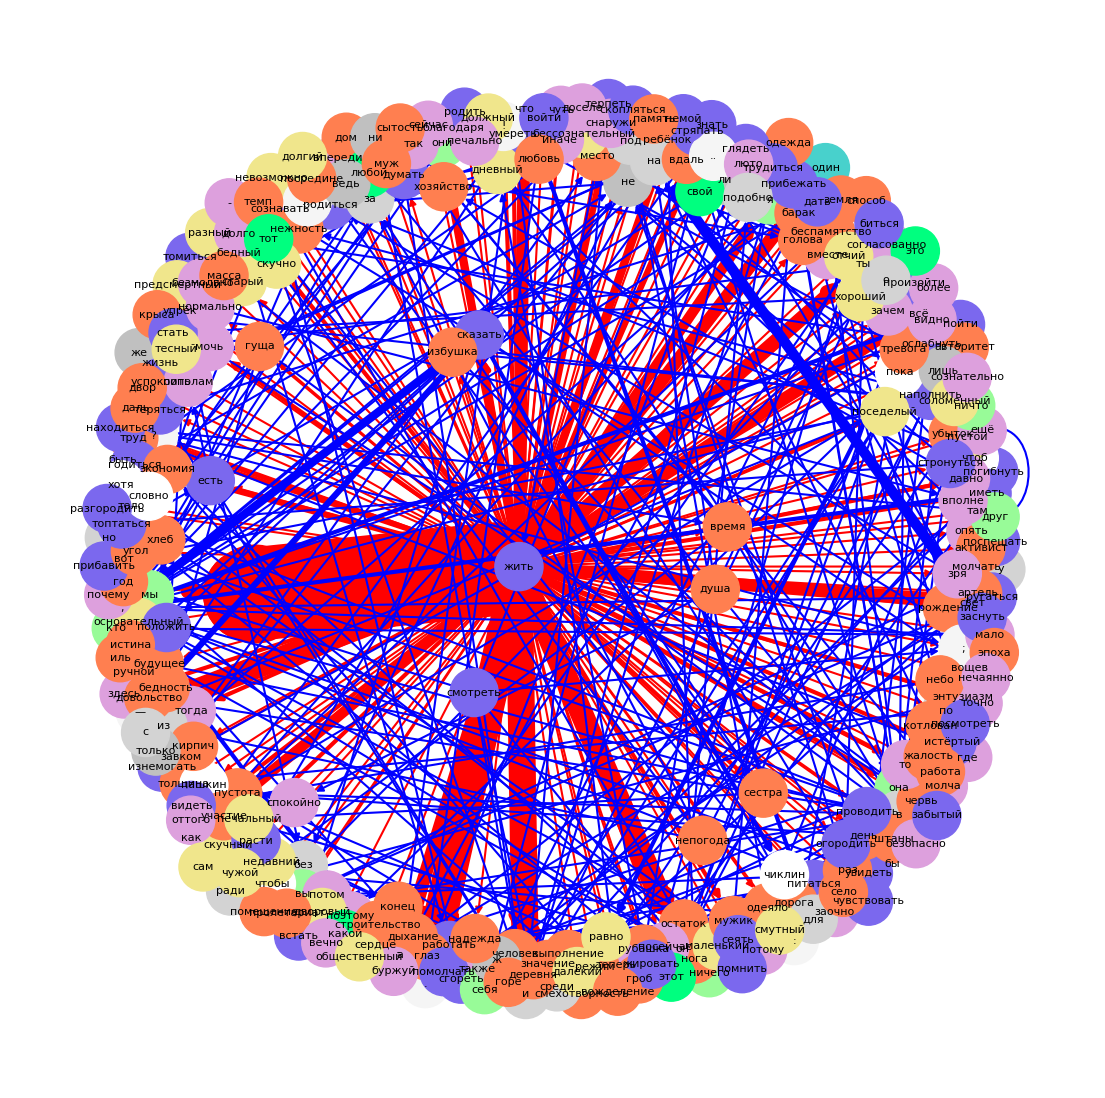

In [23]:
# horrible verb graph

counts2 = Counter()
for token in d:
    if token.text == "жить":
        for child in token.children:
            counts2[("жить", child.text)] += 1
            for grandchild in child.children:
                counts2[(child.text, grandchild.text)] += 1

DG = nx.DiGraph()
for (u, v), w in counts2.items():
    DG.add_edge(u, v, weight=w)

word_pos2 = {}
for token in d:
    if token.text in DG and token.text not in word_pos2:
        word_pos2[token.text] = token.pos_

pos2 = nx.spring_layout(DG, weight="weight", k=1.5) # so that the weights of the dependencies affect their position

widths2 = [DG[u][v]["weight"] * 1.5 for u, v in DG.edges]
edge_colors2 = ["red" if u == "жить" else "blue" for u, v in DG.edges]
node_colors2 = [pos_colors.get(word_pos2.get(n, ""), default_color) for n in DG.nodes]


fig, ax = plt.subplots(figsize=(14, 14))
nx.draw(DG, pos=pos2, ax=ax, with_labels=True,
        node_color=node_colors2, node_size=1200,
        edge_color=edge_colors2, width=widths2,
        arrows=True, font_size=8)

plt.axis("off")
plt.show()

## 4. Network analysis
**The task:** Perform network analysis of the graph. Measure the density, split the graph into communities etc. Describe and justify what and why you are doing.



I check the number of nodes and edges:

In [24]:
print(G.number_of_nodes())
print(G.number_of_edges())

84
97


In [25]:
# for the terrifying verb graph
print(DG.number_of_nodes())
print(DG.number_of_edges())

291
460


I measure the density: it is predictably low.

In [26]:
print(nx.density(G))

0.013912794033275961


In [27]:
# for the verb graph
print(nx.density(DG))

0.005450882806019671


The clustering coefficient is very low (a little higher for the verb graph); it is quite unlikely that the closest neighbors of a node will be connected to each other (this makes sense, considering we are collecting the dependencies of a single word & then their dependencies; it is not very likely for this graph to be very interconnected)

In [28]:
print(nx.average_clustering(G))

0.04676337201547286


In [29]:
# verb graph
print(nx.average_clustering(DG))

0.07508489428697046


In [30]:
# here I just looked at the number of neighbors of each node; we can see that many have just one
for node in G.nodes():
    print (node, G.degree(node))

колхоз 51
по 1
у 1
имя 1
от 1
над 1
бедный 2
в 1
путём 1
, 5
как 1
идти 4
свет 1
— 1
ведь 1
на 1
без 1
обождать 2
иль 1
ты 1
весь 1
а 1
здесь 1
сделать 1
? 1
спасть 4
ещё 1
зимой 1
мы 1
нужный 1
разлагать 4
не 4
он 1
! 2
годиться 5
вы 1
прочь 1
с 2
прекращать 4
топтаться 1
пляска 3
тяжкий 1
запеть 4
постепенно 1
голос 1
. 1
непоколебимый 1
оргдвор 1
один 1
же 1
из 1
* 2
член 2
сжечь 6
уголь 1
кузня 1
истратить 1
починить 1
тоска 1
сесть 3
плетень 1
стать 1
после 1
коммуна 3
и 3
светлый 1
что 1
это 1
мести 2
снег 1
нравиться 7
: 1
мужик 6
теперь 1
засидеть 1
хотеть 1
безмолвный 1
вслед 1
переставать 1
; 1
всё 1
работа 1
усердие 4
такой 1


In [33]:
# looked at the neighbors of one of the words that has several
list(G.adj["сжечь"])

['уголь', 'кузня', 'истратить', 'починить', 'тоска']

I calculate degree centrality. Predictably, my central word has the highest degree centrality.

In [44]:
deg = nx.degree_centrality(G)
for nodeid in sorted(deg, key=deg.get, reverse=True):
    print(nodeid, deg[nodeid])

колхоз 0.6144578313253012
нравиться 0.08433734939759037
сжечь 0.07228915662650603
мужик 0.07228915662650603
, 0.060240963855421686
годиться 0.060240963855421686
идти 0.04819277108433735
спасть 0.04819277108433735
разлагать 0.04819277108433735
не 0.04819277108433735
прекращать 0.04819277108433735
запеть 0.04819277108433735
усердие 0.04819277108433735
пляска 0.03614457831325302
сесть 0.03614457831325302
коммуна 0.03614457831325302
и 0.03614457831325302
бедный 0.024096385542168676
обождать 0.024096385542168676
! 0.024096385542168676
с 0.024096385542168676
* 0.024096385542168676
член 0.024096385542168676
мести 0.024096385542168676
по 0.012048192771084338
у 0.012048192771084338
имя 0.012048192771084338
от 0.012048192771084338
над 0.012048192771084338
в 0.012048192771084338
путём 0.012048192771084338
как 0.012048192771084338
свет 0.012048192771084338
— 0.012048192771084338
ведь 0.012048192771084338
на 0.012048192771084338
без 0.012048192771084338
иль 0.012048192771084338
ты 0.012048192771084

And betweennness centrality. We see that we have a handful of words through which closest paths go, and a lot of words through which they do not. Interestingly, the betweenness centrality of the central word is zero: my assumption is that this is because the graph is directed.

In [45]:
b = nx.betweenness_centrality(G)
for nodeid in sorted(b, key=b.get, reverse=True):
    print(nodeid, b[nodeid])

мужик 0.001028504260946224
сжечь 0.0007346459006758743
нравиться 0.0006244490155744931
идти 0.0004407875404055246
спасть 0.0004407875404055246
годиться 0.00033059065530414343
запеть 0.0002938583602703497
сесть 0.0002938583602703497
разлагать 0.00018366147516896857
прекращать 0.00018366147516896857
обождать 0.00014692918013517486
пляска 0.00014692918013517486
коммуна 0.00014692918013517486
мести 0.00014692918013517486
усердие 0.00014692918013517486
колхоз 0.0
по 0.0
у 0.0
имя 0.0
от 0.0
над 0.0
бедный 0.0
в 0.0
путём 0.0
, 0.0
как 0.0
свет 0.0
— 0.0
ведь 0.0
на 0.0
без 0.0
иль 0.0
ты 0.0
весь 0.0
а 0.0
здесь 0.0
сделать 0.0
? 0.0
ещё 0.0
зимой 0.0
мы 0.0
нужный 0.0
не 0.0
он 0.0
! 0.0
вы 0.0
прочь 0.0
с 0.0
топтаться 0.0
тяжкий 0.0
постепенно 0.0
голос 0.0
. 0.0
непоколебимый 0.0
оргдвор 0.0
один 0.0
же 0.0
из 0.0
* 0.0
член 0.0
уголь 0.0
кузня 0.0
истратить 0.0
починить 0.0
тоска 0.0
плетень 0.0
стать 0.0
после 0.0
и 0.0
светлый 0.0
что 0.0
это 0.0
снег 0.0
: 0.0
теперь 0.0
засидеть 0.

Let us check this by converting the graph to undirected. Now our central word has the highest betweenness centrality. The order of the other words is also somewhat affected (and some more words gained non-zero values).

In [46]:
btw = nx.betweenness_centrality(G.to_undirected())
for nodeid in sorted(btw, key=btw.get, reverse=True):
    print(nodeid, btw[nodeid])

колхоз 0.9512097169164462
сжечь 0.11754334410813988
нравиться 0.10049466157312176
мужик 0.07220099911842492
идти 0.07140758154569499
спасть 0.07140758154569499
годиться 0.052830835537271054
запеть 0.047898912724067
сесть 0.047898912724067
разлагать 0.029126261142129503
прекращать 0.029126261142129503
усердие 0.02424331472230385
обождать 0.024096385542168676
пляска 0.024096385542168676
коммуна 0.024096385542168676
мести 0.024096385542168676
не 0.007297482613380351
, 0.004701733764325595
и 0.0005877167205406994
по 0.0
у 0.0
имя 0.0
от 0.0
над 0.0
бедный 0.0
в 0.0
путём 0.0
как 0.0
свет 0.0
— 0.0
ведь 0.0
на 0.0
без 0.0
иль 0.0
ты 0.0
весь 0.0
а 0.0
здесь 0.0
сделать 0.0
? 0.0
ещё 0.0
зимой 0.0
мы 0.0
нужный 0.0
он 0.0
! 0.0
вы 0.0
прочь 0.0
с 0.0
топтаться 0.0
тяжкий 0.0
постепенно 0.0
голос 0.0
. 0.0
непоколебимый 0.0
оргдвор 0.0
один 0.0
же 0.0
из 0.0
* 0.0
член 0.0
уголь 0.0
кузня 0.0
истратить 0.0
починить 0.0
тоска 0.0
плетень 0.0
стать 0.0
после 0.0
светлый 0.0
что 0.0
это 0.0
снег

I did not check eigencentrality because most of my nodes are not well-connected, and I imagined it would be noisy.

I did look at closeness centrality as well, though I did not expect it to be very interesting; it paints a similar picture to betweenness centrality...

In [42]:
close = nx.closeness_centrality(G.to_undirected())
for nodeid in sorted(close, key=close.get, reverse=True):
    print(nodeid, close[nodeid])

колхоз 0.7217391304347827
нравиться 0.453551912568306
мужик 0.45108695652173914
, 0.44385026737967914
сжечь 0.44385026737967914
годиться 0.4368421052631579
идти 0.43455497382198954
спасть 0.43455497382198954
разлагать 0.4322916666666667
прекращать 0.4322916666666667
запеть 0.4322916666666667
бедный 0.43005181347150256
! 0.43005181347150256
сесть 0.43005181347150256
и 0.43005181347150256
усердие 0.43005181347150256
пляска 0.42783505154639173
коммуна 0.42783505154639173
обождать 0.4256410256410256
с 0.4256410256410256
мести 0.4256410256410256
* 0.42346938775510207
член 0.42346938775510207
по 0.4213197969543147
у 0.4213197969543147
имя 0.4213197969543147
от 0.4213197969543147
над 0.4213197969543147
в 0.4213197969543147
путём 0.4213197969543147
как 0.4213197969543147
— 0.4213197969543147
ведь 0.4213197969543147
на 0.4213197969543147
без 0.4213197969543147
ты 0.4213197969543147
весь 0.4213197969543147
а 0.4213197969543147
здесь 0.4213197969543147
сделать 0.4213197969543147
? 0.4213197969543

Now I try to split the graph into communities.

In [35]:
from networkx.algorithms import community

I tried the greedy modularity algorithm and the Girvan-Newman one.

In [37]:
communities_generator_ = community.greedy_modularity_communities(G)
communities_generator_

[frozenset({'*',
            '.',
            '?',
            'а',
            'без',
            'безмолвный',
            'в',
            'ведь',
            'весь',
            'же',
            'здесь',
            'зимой',
            'из',
            'имя',
            'как',
            'колхоз',
            'мы',
            'на',
            'над',
            'нужный',
            'один',
            'от',
            'по',
            'после',
            'путём',
            'сделать',
            'ты',
            'у',
            'член',
            'что',
            'это',
            '—'}),
 frozenset({',',
            'голос',
            'запеть',
            'не',
            'он',
            'пляска',
            'постепенно',
            'прекращать',
            'разлагать',
            'топтаться',
            'тяжкий'}),
 frozenset({':',
            ';',
            'бедный',
            'всё',
            'засидеть',
            'мужик',
            'нрави

In [36]:
communities_generator2 = community.girvan_newman(G) # takes out one by one edges with highest betweenness centrality
top_level_communities = next(communities_generator2)
next_level_communities = next(communities_generator2)
third_level_communities = next(communities_generator2)
forth_level_communities = next(communities_generator2)
fifth_level_communities = next(communities_generator2)
sixth_level_communities = next(communities_generator2)
print("top level communities:", sorted(map(sorted, top_level_communities)))
print("next level communities:", sorted(map(sorted, next_level_communities)))
print("third level communities:", sorted(map(sorted, third_level_communities)))
print("forth level communities:", sorted(map(sorted, forth_level_communities)))
print("fifth level communities:", sorted(map(sorted, fifth_level_communities)))
print("sixth level communities:", sorted(map(sorted, sixth_level_communities)))

top level communities: [['!', '*', ',', '.', ':', ';', '?', 'а', 'бедный', 'без', 'безмолвный', 'в', 'ведь', 'весь', 'вслед', 'всё', 'вы', 'годиться', 'голос', 'ещё', 'же', 'запеть', 'засидеть', 'здесь', 'зимой', 'и', 'идти', 'из', 'иль', 'имя', 'как', 'колхоз', 'коммуна', 'мести', 'мужик', 'мы', 'на', 'над', 'не', 'непоколебимый', 'нравиться', 'нужный', 'обождать', 'один', 'он', 'оргдвор', 'от', 'переставать', 'плетень', 'пляска', 'по', 'после', 'постепенно', 'прекращать', 'прочь', 'путём', 'работа', 'разлагать', 'с', 'свет', 'светлый', 'сделать', 'сесть', 'снег', 'спасть', 'стать', 'такой', 'теперь', 'топтаться', 'ты', 'тяжкий', 'у', 'усердие', 'хотеть', 'член', 'что', 'это', '—'], ['истратить', 'кузня', 'починить', 'сжечь', 'тоска', 'уголь']]
next level communities: [['!', '*', ',', '.', '?', 'а', 'без', 'безмолвный', 'в', 'ведь', 'весь', 'вслед', 'вы', 'годиться', 'голос', 'ещё', 'же', 'запеть', 'здесь', 'зимой', 'и', 'идти', 'из', 'иль', 'имя', 'как', 'колхоз', 'коммуна', 'мести',

To my mind, the community-splitting does not appear particularly informative at all (though there are some similarities between the two analyses). (These might just be some children & their dependencies? I am not sure...)

Out of curiosity I decided to split the horrible verb graph into communities as well.

In [38]:
communities_generator3 = community.girvan_newman(DG) # takes out one by one edges with highest betweenness centrality
top_level_communities = next(communities_generator3)
next_level_communities = next(communities_generator3)
third_level_communities = next(communities_generator3)
forth_level_communities = next(communities_generator3)
fifth_level_communities = next(communities_generator3)
sixth_level_communities = next(communities_generator3)
print("top level communities:", sorted(map(sorted, top_level_communities)))
print("next level communities:", sorted(map(sorted, next_level_communities)))
print("third level communities:", sorted(map(sorted, third_level_communities)))
print("forth level communities:", sorted(map(sorted, forth_level_communities)))
print("fifth level communities:", sorted(map(sorted, fifth_level_communities)))
print("sixth level communities:", sorted(map(sorted, sixth_level_communities)))

top level communities: [['!', ',', '-', '.', '..', ':', ';', '?', 'а', 'авторитет', 'активист', 'артель', 'барак', 'бедность', 'бедный', 'без', 'безмолвно', 'безопасно', 'беспамятство', 'бессознательный', 'биться', 'благодаря', 'более', 'будущее', 'буржуй', 'бы', 'быть', 'в', 'вдаль', 'ведь', 'вечно', 'видеть', 'видно', 'вместе', 'вожделение', 'войти', 'вот', 'впереди', 'вполне', 'время', 'всё', 'вы', 'выполнение', 'где', 'глаз', 'глядеть', 'год', 'годиться', 'голова', 'горе', 'гроб', 'гуща', 'давно', 'даль', 'далёкий', 'дать', 'двор', 'дворовый', 'день', 'деревня', 'для', 'дневный', 'довольство', 'долгий', 'долго', 'должный', 'дом', 'доселе', 'друг', 'думать', 'душа', 'дыхание', 'есть', 'ещё', 'ж', 'жалость', 'же', 'жизнь', 'жировать', 'жить', 'за', 'забытый', 'завком', 'заочно', 'заснуть', 'зачем', 'здесь', 'земля', 'знать', 'значение', 'зря', 'и', 'из', 'избушка', 'изнемогать', 'иль', 'иметь', 'иначе', 'истина', 'истёртый', 'как', 'какой', 'кирпич', 'конец', 'котлован', 'крыса', 'кт

In [39]:
communities_generator4 = community.greedy_modularity_communities(DG)
communities_generator4

[frozenset({'.',
            '..',
            '?',
            'авторитет',
            'активист',
            'безопасно',
            'более',
            'бы',
            'ведь',
            'вечно',
            'впереди',
            'вполне',
            'всё',
            'давно',
            'доселе',
            'дыхание',
            'ещё',
            'ж',
            'жизнь',
            'жить',
            'забытый',
            'заочно',
            'зачем',
            'здесь',
            'зря',
            'иначе',
            'любой',
            'люто',
            'масса',
            'молчать',
            'мочь',
            'нечаянно',
            'нормально',
            'одеяло',
            'они',
            'опять',
            'отчий',
            'пашкин',
            'печально',
            'по',
            'под',
            'почему',
            'предсмертный',
            'пролетариат',
            'равно',
            'раз',
            'разный',
 

Likewise, I cannot see any particular meaning in this (besides, I guess, the idea that the Girwan-Newman algorithm seems to put the punctuation into one community here, which does not appear particularly interesting...)

I check the amount of components, as well as the diameter and the average shortest path length; for all of these things I need to convert the graph to undirected first:

In [40]:
print("Components:", nx.number_connected_components(G.to_undirected()))
print("diameter:", nx.diameter(G.to_undirected()))
print("Average shortest path:", nx.average_shortest_path_length(G.to_undirected()))

Components: 1
diameter: 4
Average shortest path: 2.683304647160069


(Predictably, we have one component)

I also looked at the bridges (edges whose removal disconnects the graph) and the articulation points (nodes whose removal disconnects the graph)

In [49]:
bridges = list(nx.bridges(G.to_undirected()))
arts    = list(nx.articulation_points(G.to_undirected()))

In [50]:
print(bridges)

[('колхоз', 'по'), ('колхоз', 'у'), ('колхоз', 'имя'), ('колхоз', 'от'), ('колхоз', 'над'), ('колхоз', 'в'), ('колхоз', 'путём'), ('колхоз', 'как'), ('колхоз', 'идти'), ('колхоз', '—'), ('колхоз', 'ведь'), ('колхоз', 'на'), ('колхоз', 'без'), ('колхоз', 'обождать'), ('колхоз', 'ты'), ('колхоз', 'весь'), ('колхоз', 'а'), ('колхоз', 'здесь'), ('колхоз', 'сделать'), ('колхоз', '?'), ('колхоз', 'спасть'), ('колхоз', 'зимой'), ('колхоз', 'мы'), ('колхоз', 'нужный'), ('колхоз', '.'), ('колхоз', 'один'), ('колхоз', 'же'), ('колхоз', 'из'), ('колхоз', 'сжечь'), ('колхоз', 'сесть'), ('колхоз', 'после'), ('колхоз', 'что'), ('колхоз', 'это'), ('колхоз', 'мести'), ('колхоз', 'безмолвный'), ('идти', 'свет'), ('идти', 'вслед'), ('идти', 'переставать'), ('обождать', 'иль'), ('спасть', 'ещё'), ('спасть', 'непоколебимый'), ('спасть', 'оргдвор'), ('разлагать', 'он'), ('годиться', 'вы'), ('годиться', 'прочь'), ('прекращать', 'топтаться'), ('пляска', 'тяжкий'), ('запеть', 'постепенно'), ('запеть', 'голос'

In [51]:
print(arts)

['нравиться', 'прекращать', 'пляска', 'запеть', 'разлагать', 'годиться', 'мужик', 'идти', 'обождать', 'спасть', 'коммуна', 'усердие', 'сжечь', 'сесть', 'мести', 'колхоз']


In [57]:
# the articulation points = the top 16 words with the highest betweenness centrality:
top16 = sorted(btw.items(), key=lambda x: x[1], reverse=True)[:16]
for word, score in top16:
    print(f"{word:15s} {score:.4f}")

колхоз          0.9512
сжечь           0.1175
нравиться       0.1005
мужик           0.0722
идти            0.0714
спасть          0.0714
годиться        0.0528
запеть          0.0479
сесть           0.0479
разлагать       0.0291
прекращать      0.0291
усердие         0.0242
обождать        0.0241
пляска          0.0241
коммуна         0.0241
мести           0.0241


Besides the central word, the articulation points are predominantly verbs and then nouns. I imagine it is expected for them to have more dependencies and matter more for this reason.

In [55]:
print(G.number_of_edges(), G.number_of_nodes())

97 84


In [53]:
print(len(bridges), len(arts))

66 16


I also checked degree assortativity; it is negative (suggesting that my high-connected nodes are largely connected to low-connected nodes, that is, that my graph is tree-like)

In [41]:
print("Degree assortativity:", nx.degree_assortativity_coefficient(G.to_undirected()))

Degree assortativity: -0.3970824629477875


## 5. Conclusions
**Q**: Could you draw any meaningful conclusions from your analysis? Provide a short (a couple of sentences) answer.

**A**: Overall, this reveals pretty limited information. It suggests that the graph is quite sparse and tree-like (which appears expected for dependencies?), the word at the center is predictably the most connected of them all. The community-splitting does not appear to be particularly informative, or, at least, I cannot really see any meaning in it (again, perhaps due to the low density?). Nonetheless, some words with higher degree centrality (more neighbors) and higher betweenness centrality can be identified (the words with the highest betweenness centrality are also (predictably) the words that would disconnect the graph if removed). Also, I suspect that lemmatizing the text prior to identifying the dependencies may be causing some problems in dependency identification...